In [4]:
import pandas as pd
df = pd.read_csv("C:\\Users\\MJ_SHUKE\\Downloads\\444\\Country_Consumption_TWH.csv")
df2 = pd.read_csv("C:\\Users\\MJ_SHUKE\\Downloads\\444\\renewablePowerGeneration97-17.csv")

In [39]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 45 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Year                  31 non-null     float64
 1   China                 31 non-null     float64
 2   United States         31 non-null     float64
 3   Brazil                31 non-null     float64
 4   Belgium               31 non-null     float64
 5   Czechia               31 non-null     float64
 6   France                31 non-null     float64
 7   Germany               31 non-null     float64
 8   Italy                 31 non-null     float64
 9   Netherlands           31 non-null     float64
 10  Poland                31 non-null     float64
 11  Portugal              31 non-null     float64
 12  Romania               31 non-null     float64
 13  Spain                 31 non-null     float64
 14  Sweden                31 non-null     float64
 15  United Kingdom        31 

,Year,China,United States,Brazil,Belgium,Czechia,France,Germany,Italy,Netherlands,...,Australia,New Zealand,Algeria,Egypt,Nigeria,South Africa,Iran,Kuwait,Saudi Arabia,United Arab Emirates
0,1990.0,874.0,1910.0,141.0,48.0,50.0,225.0,351.0,147.0,67.0,...,86.0,14.0,22.0,33.0,66.0,90.0,69.0,9.0,58.0,20.0
1,1991.0,848.0,1925.0,143.0,50.0,45.0,237.0,344.0,150.0,69.0,...,85.0,14.0,23.0,33.0,70.0,92.0,77.0,3.0,68.0,23.0
2,1992.0,877.0,1964.0,145.0,51.0,44.0,234.0,338.0,149.0,69.0,...,87.0,14.0,24.0,34.0,72.0,88.0,81.0,9.0,77.0,22.0
3,1993.0,929.0,1998.0,148.0,49.0,43.0,238.0,335.0,149.0,70.0,...,91.0,15.0,24.0,35.0,74.0,94.0,87.0,12.0,80.0,23.0
4,1994.0,973.0,2036.0,156.0,52.0,41.0,231.0,333.0,147.0,70.0,...,91.0,15.0,23.0,34.0,72.0,98.0,97.0,14.0,84.0,26.0


In [40]:
df2.info()
df2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Year              28 non-null     int64  
 1   Hydro(TWh)        28 non-null     float64
 2   Biofuel(TWh)      28 non-null     float64
 3   Solar PV (TWh)    28 non-null     float64
 4   Geothermal (TWh)  28 non-null     float64
dtypes: float64(4), int64(1)
memory usage: 1.2 KB


,Year,Hydro(TWh),Biofuel(TWh),Solar PV (TWh),Geothermal (TWh)
0,1990,2191.67,3.88,0.09,36.42
1,1991,2268.63,4.19,0.10,37.39
2,1992,2267.16,4.63,0.12,39.30
3,1993,2397.67,5.61,0.15,40.23
4,1994,2419.73,7.31,0.17,41.05


In [8]:
#merging datsets based on year
merged_df = pd.merge(df, df2, on='Year', how='inner')
display(merged_df.head())

,Year,China,United States,Brazil,Belgium,Czechia,France,Germany,Italy,Netherlands,...,Nigeria,South Africa,Iran,Kuwait,Saudi Arabia,United Arab Emirates,Hydro(TWh),Biofuel(TWh),Solar PV (TWh),Geothermal (TWh)
0,1990.0,874.0,1910.0,141.0,48.0,50.0,225.0,351.0,147.0,67.0,...,66.0,90.0,69.0,9.0,58.0,20.0,2191.67,3.88,0.09,36.42
1,1991.0,848.0,1925.0,143.0,50.0,45.0,237.0,344.0,150.0,69.0,...,70.0,92.0,77.0,3.0,68.0,23.0,2268.63,4.19,0.10,37.39
2,1992.0,877.0,1964.0,145.0,51.0,44.0,234.0,338.0,149.0,69.0,...,72.0,88.0,81.0,9.0,77.0,22.0,2267.16,4.63,0.12,39.30
3,1993.0,929.0,1998.0,148.0,49.0,43.0,238.0,335.0,149.0,70.0,...,74.0,94.0,87.0,12.0,80.0,23.0,2397.67,5.61,0.15,40.23
4,1994.0,973.0,2036.0,156.0,52.0,41.0,231.0,333.0,147.0,70.0,...,72.0,98.0,97.0,14.0,84.0,26.0,2419.73,7.31,0.17,41.05


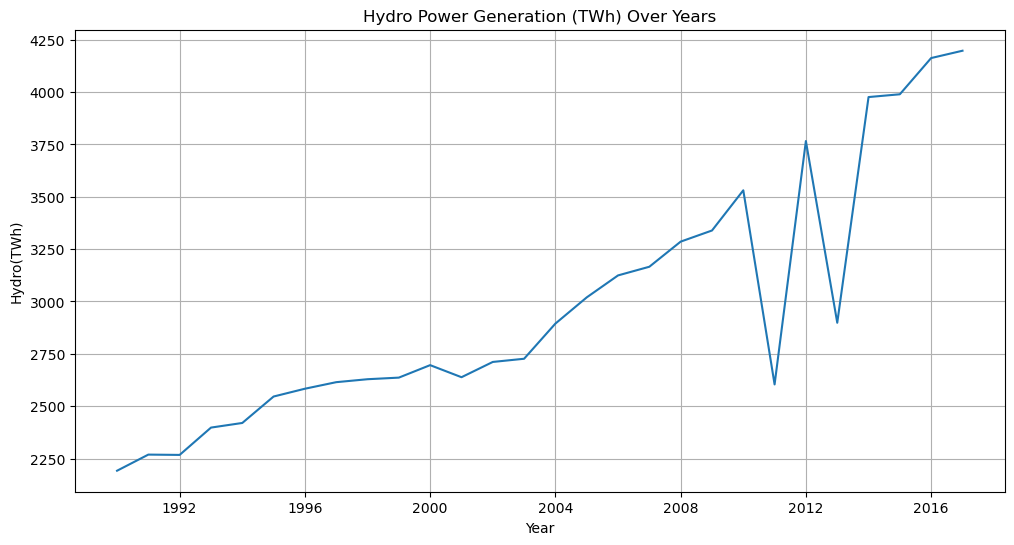

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(x='Year', y='Hydro(TWh)', data=merged_df)
plt.title('Hydro Power Generation (TWh) Over Years')
plt.xlabel('Year')
plt.ylabel('Hydro(TWh)')
plt.grid(True)
plt.show()

In [47]:
# Identify country columns and energy generation columns
country_columns = [col for col in merged_df.columns if col not in ['Hydro(TWh)', 'Biofuel(TWh)', 'Solar PV (TWh)', 'Geothermal (TWh)', 'Total_Renewable_TWh', 'Total_Renewable_TWh_lag1', 'Total_Renewable_TWh_lag2']]
generation = [col for col in merged_df.columns if col not in country_columns]
# Calculate total consumption and generation
merged_df['Total_Consumption_TWh'] = merged_df[country_columns].sum(axis=1)
merged_df['Total_Generation_TWh'] = merged_df[generation].sum(axis=1)

print("DataFrame with new 'Total_Consumption_TWh' and 'Total_Generation_TWh':")
display(merged_df[['Total_Consumption_TWh']].head())
display(merged_df[['Total_Generation_TWh']].head())

DataFrame with new 'Total_Consumption_TWh' and 'Total_Generation_TWh':


,Total_Consumption_TWh
Year,
1990-01-01,44387.06
1991-01-01,102532.31
1992-01-01,160814.21
1993-01-01,161977.66
1994-01-01,162978.26


,Total_Generation_TWh
Year,
1990-01-01,2232.06
1991-01-01,2310.31
1992-01-01,2311.21
1993-01-01,2443.66
1994-01-01,2468.26


In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the relevant columns for correlation analysis
renewable_sources = ['Hydro(TWh)', 'Biofuel(TWh)', 'Solar PV (TWh)', 'Geothermal (TWh)', 'Total_Consumption_TWh']
correlation_matrix = merged_df[renewable_sources].corr()

print("Correlation Matrix between Renewable Sources and Total Generation:")
display(correlation_matrix)

Correlation Matrix between Renewable Sources and Total Generation:


,Hydro(TWh),Biofuel(TWh),Solar PV (TWh),Geothermal (TWh),Total_Consumption_TWh
Hydro(TWh),1.000000,0.870333,0.795868,0.916762,0.879574
Biofuel(TWh),0.870333,1.000000,0.953079,0.908150,0.865515
Solar PV (TWh),0.795868,0.953079,1.000000,0.780185,0.699991
Geothermal (TWh),0.916762,0.908150,0.780185,1.000000,0.982789
Total_Consumption_TWh,0.879574,0.865515,0.699991,0.982789,1.000000


In [32]:
# Create lagged features for Total_Consumption_TWh
merged_df['Total_Consumption_TWh_lag1'] = merged_df['Total_Consumption_TWh'].shift(1)
merged_df['Total_Consumption_TWh_lag2'] = merged_df['Total_Consumption_TWh'].shift(2)

# Drop rows with NaN values resulting from lagging
merged_df_ml = merged_df.dropna(subset=['Total_Consumption_TWh_lag1', 'Total_Consumption_TWh_lag2']).copy()

print("DataFrame with lagged features:")
display(merged_df_ml[['Total_Consumption_TWh', 'Total_Consumption_TWh_lag1', 'Total_Consumption_TWh_lag2']].head())

DataFrame with lagged features:


,Total_Consumption_TWh,Total_Consumption_TWh_lag1,Total_Consumption_TWh_lag2
Year,,,
1992-01-01,19438.0,19378.0,19250.0
1993-01-01,19626.0,19438.0,19378.0
1994-01-01,19720.0,19626.0,19438.0
1995-01-01,20138.0,19720.0,19626.0
1996-01-01,20522.0,20138.0,19720.0


In [52]:
# Create lagged features for Total_Generation_TWh
merged_df['Total_Generation_TWh_lag1'] = merged_df['Total_Generation_TWh'].shift(1)
merged_df['Total_Generation_TWh_lag2'] = merged_df['Total_Generation_TWh'].shift(2)

# Drop rows with NaN values resulting from lagging
merged_df_ml2 = merged_df.dropna(subset=['Total_Generation_TWh_lag1', 'Total_Generation_TWh_lag2']).copy()

print("DataFrame with lagged features:")
display(merged_df_ml[['Total_Generation_TWh', 'Total_Generation_TWh_lag1', 'Total_Generation_TWh_lag2']].head())

DataFrame with lagged features:


,Total_Generation_TWh,Total_Generation_TWh_lag1,Total_Generation_TWh_lag2
Year,,,
1992-01-01,2311.21,2310.31,2232.06
1993-01-01,2443.66,2311.21,2310.31
1994-01-01,2468.26,2443.66,2311.21
1995-01-01,2593.99,2468.26,2443.66
1996-01-01,2635.03,2593.99,2468.26


In [54]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Define features (X) and target (y)
# We'll use lagged renewable energy and total consumption as features
X = merged_df_ml[['Total_Consumption_TWh_lag1', 'Total_Consumption_TWh_lag2', 'Total_Consumption_TWh']]
y = merged_df_ml['Total_Consumption_TWh']

# Split the data into training and testing sets
# For time series data, it's crucial to split chronologically
train_size = int(len(X) * 0.8)
X_train, X_test = X[0:train_size], X[train_size:len(X)]
y_train, y_test = y[0:train_size], y[train_size:len(y)]

print(f"Training set size: {len(X_train)}")
print(f"Testing set size: {len(X_test)}")

# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nMean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

# Display actual vs predicted values
results_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred}, index=y_test.index)
display(results_df)

Training set size: 20
Testing set size: 6

Mean Squared Error (MSE): 0.00
R-squared (R2): 1.00


,Actual,Predicted
Year,,
2012-01-01,225708.30,225708.30
2013-01-01,227894.02,227894.02
2014-01-01,231504.85,231504.85
2015-01-01,233326.90,233326.90
2016-01-01,234553.73,234553.73
2017-01-01,236251.49,236251.49


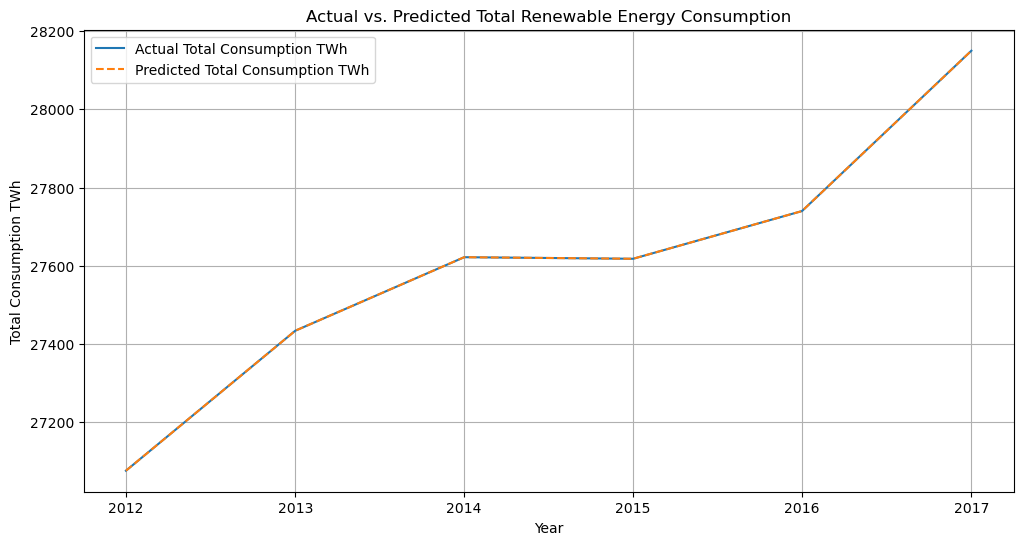

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(x=results_df.index, y='Actual', data=results_df, label='Actual Total Consumption TWh')
sns.lineplot(x=results_df.index, y='Predicted', data=results_df, label='Predicted Total Consumption TWh', linestyle='--')
plt.title('Actual vs. Predicted Total Renewable Energy Consumption')
plt.xlabel('Year')
plt.ylabel('Total Consumption TWh')
plt.legend()
plt.grid(True)
plt.show()

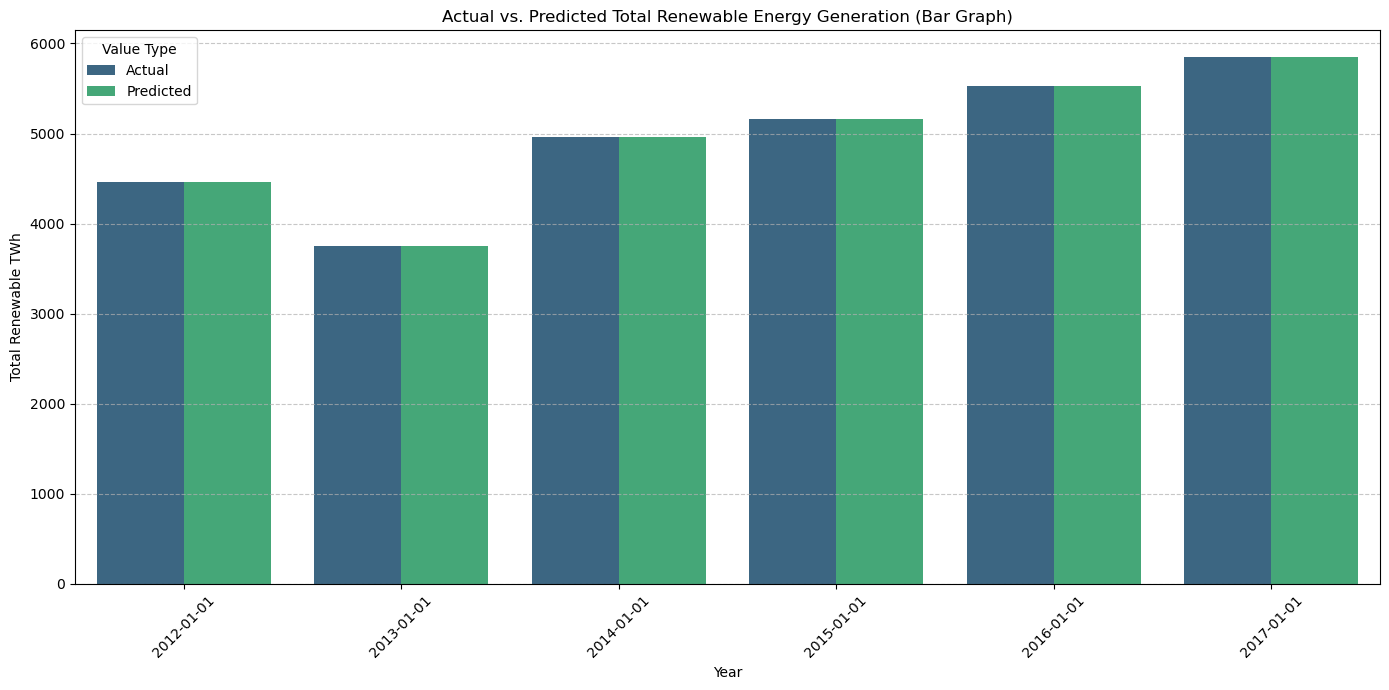

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for grouped bar chart
results_melted = results_df.reset_index().melt(id_vars='Year', var_name='Type', value_name='Total Renewable TWh')

plt.figure(figsize=(14, 7))
sns.barplot(x='Year', y='Total Renewable TWh', hue='Type', data=results_melted, palette='viridis')
plt.title('Actual vs. Predicted Total Renewable Energy Generation (Bar Graph)')
plt.xlabel('Year')
plt.ylabel('Total Renewable TWh')
plt.legend(title='Value Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [55]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Define features (X) and target (y)
# We'll use lagged renewable energy and total consumption as features
X = merged_df_ml[['Total_Generation_TWh_lag1', 'Total_Generation_TWh_lag2', 'Total_Generation_TWh']]
y = merged_df_ml['Total_Generation_TWh']

# Split the data into training and testing sets
# For time series data, it's crucial to split chronologically
train_size = int(len(X) * 0.8)
X_train, X_test = X[0:train_size], X[train_size:len(X)]
y_train, y_test = y[0:train_size], y[train_size:len(y)]

print(f"Training set size: {len(X_train)}")
print(f"Testing set size: {len(X_test)}")

# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nMean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

# Display actual vs predicted values
results_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred}, index=y_test.index)
display(results_df)

Training set size: 20
Testing set size: 6

Mean Squared Error (MSE): 0.00
R-squared (R2): 1.00


,Actual,Predicted
Year,,
2012-01-01,4460.30,4460.30
2013-01-01,3756.02,3756.02
2014-01-01,4961.85,4961.85
2015-01-01,5158.90,5158.90
2016-01-01,5531.73,5531.73
2017-01-01,5853.49,5853.49


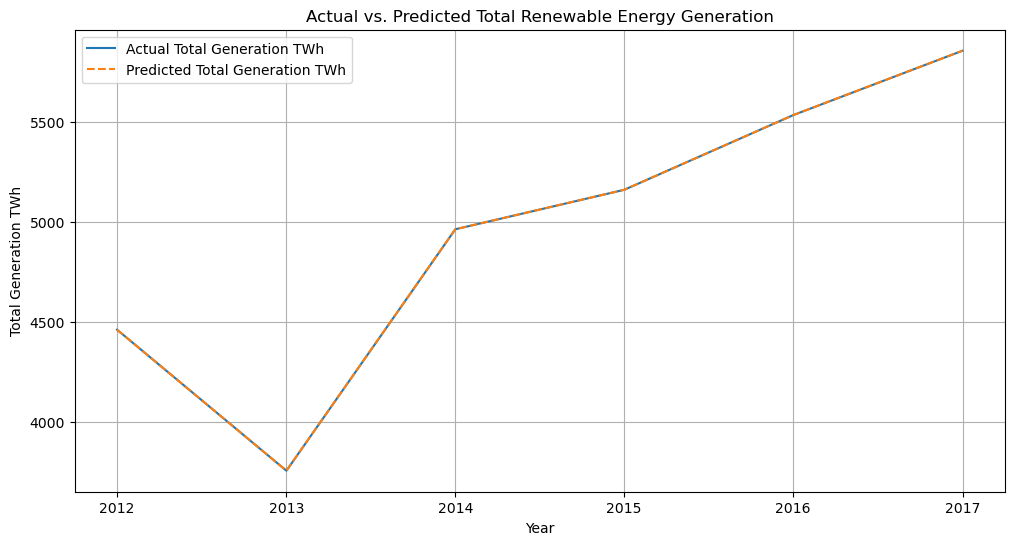

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(x=results_df.index, y='Actual', data=results_df, label='Actual Total Generation TWh')
sns.lineplot(x=results_df.index, y='Predicted', data=results_df, label='Predicted Total Generation TWh', linestyle='--')
plt.title('Actual vs. Predicted Total Renewable Energy Generation')
plt.xlabel('Year')
plt.ylabel('Total Generation TWh')
plt.legend()
plt.grid(True)
plt.show()

2026-01-24 14:52:33.707 Session state does not function when running a script without `streamlit run`


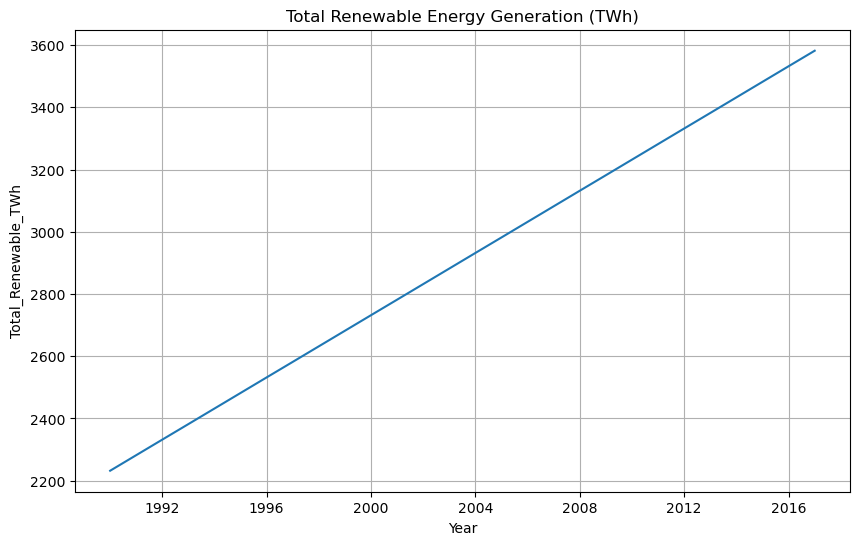

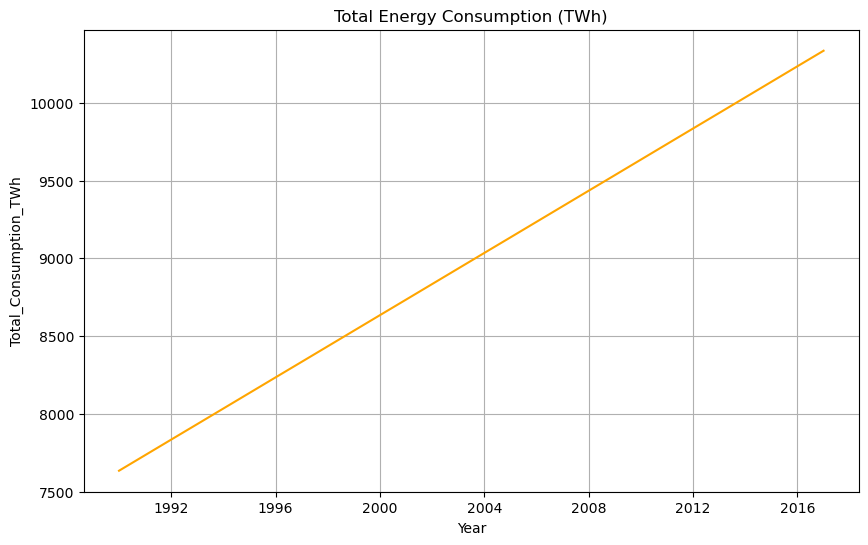

In [57]:
#STREAMLIT APP
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(layout="wide")
st.title("Renewable Energy Grid Management Dashboard")

if 'merged_df' not in st.session_state:
    st.warning("merged_df not found in session state. Please run the data loading and processing cells first.")
    st.session_state.merged_df = pd.DataFrame({
        'Year': pd.to_datetime(pd.Series(range(1990, 2018)), format='%Y'),
        'Total_Renewable_TWh': [2232.06 + i*50 for i in range(28)],
        'Total_Consumption_TWh': [7635.0 + i*100 for i in range(28)],
        'Hydro(TWh)': [2191.67 + i*40 for i in range(28)],
        'Solar PV (TWh)': [0.09 + i*5 for i in range(28)]
    }).set_index('Year')

merged_df = st.session_state.merged_df

st.subheader("Overview of Merged Data")
st.write(merged_df.head())


# --- Basic Visualization: Total Renewable Energy Generation Trend ---
st.subheader("Total Renewable Energy Generation Over Time")
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x=merged_df.index, y='Total_Renewable_TWh', data=merged_df, ax=ax)
ax.set_title('Total Renewable Energy Generation (TWh)')
ax.set_xlabel('Year')
ax.set_ylabel('Total_Renewable_TWh')
ax.grid(True)
st.pyplot(fig)

# --- Basic Visualization: Total Consumption Trend ---
st.subheader("Total Energy Consumption Over Time")
fig2, ax2 = plt.subplots(figsize=(10, 6))
sns.lineplot(x=merged_df.index, y='Total_Consumption_TWh', data=merged_df, ax=ax2, color='orange')
ax2.set_title('Total Energy Consumption (TWh)')
ax2.set_xlabel('Year')
ax2.set_ylabel('Total_Consumption_TWh')
ax2.grid(True)
st.pyplot(fig2)

st.write("More features and predictions will be added here!")